# Catalog visualization interface

This notebook is intentionally thin. Reusable logic belongs in `qq_helpers.py`; this file only sets paths, loads data, calls plotting functions, and saves outputs.

In [11]:
from pathlib import Path
import sys
import importlib

import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# Folder where the central helper lives
HELPER_DIR = Path("/home/elizabeth/soft/src/QuickQuake/quickquake").resolve()

if str(HELPER_DIR) not in sys.path:
    sys.path.insert(0, str(HELPER_DIR))

import qq_helpers_integrated as h
importlib.reload(h)

print("helpers:", h.__file__)

helpers: /home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers_integrated.py


## User settings

In [32]:
#VOLCANO = "aniakchak_0.1"

WORKDIR = Path("/home/elizabeth/soft/src/QuickQuake/quickquake").resolve()
DATA_ROOT = Path("/home/elizabeth/soft/src/QuickQuake/data").resolve()

CATALOG_CSV = DATA_ROOT / "merged/output/GAMMA_hypodd_catalog_qcfiltered.csv"
STATIONS_JSON = DATA_ROOT / "merged/input/GAMMA_station_list.json"
IMAGE_DIR = h.ensure_dir(WORKDIR / "images")

START = "2021-07-29T00:00:00Z"
END = "2021-07-30T00:00:00Z"

DEPTH_MAX = 50.0
EXAGG = 1.0
VIEW_ELEV = 10.0
VIEW_AZIM = 265.0

## Column mapping and data load

In [33]:
catc = h.CatalogCols(
    time="time",
    lat="latitude",
    lon="longitude",
    depth_km="depth_km",
    mag="magnitude",
)

stc = h.StationCols(
    station_id="station",
    lat="latitude",
    lon="longitude",
    elev_km="elev_km",
)

df_catalog = h.load_catalog_csv(CATALOG_CSV, catc=catc)
df_stations = h.load_stations_json(STATIONS_JSON)

print("Catalog shape:", df_catalog.shape)
print("Catalog columns:", df_catalog.columns.tolist())
print("Stations shape:", df_stations.shape)
print("Stations columns:", df_stations.columns.tolist())

display(df_catalog.head())
display(df_stations.head())

Catalog shape: (13, 7)
Catalog columns: ['time', 'latitude', 'longitude', 'depth_km', 'magnitude', 'event_id', 'pc_ratio_energy']
Stations shape: (11, 7)
Stations columns: ['station', 'component', 'elevation(m)', 'latitude', 'longitude', 'response', 'unit']


,time,latitude,longitude,depth_km,magnitude,event_id,pc_ratio_energy
0,2021-07-29 17:33:07.360000+00:00,55.219165,-161.051774,23.67,1.41,10,7.79
1,2021-07-29 17:52:11.340000+00:00,55.232768,-160.725781,36.79,1.70,12,5.03
2,2021-07-29 18:14:38.820000+00:00,55.228324,-161.610205,11.01,1.52,13,22.72
3,2021-07-29 18:17:43.200000+00:00,55.148739,-161.212240,13.25,1.04,14,6.34
4,2021-07-29 18:38:15.040000+00:00,55.213757,-161.110563,35.26,1.74,15,5.93


,station,component,elevation(m),latitude,longitude,response,unit
0,AV.DEER..BH,"[E, N, Z]",392.3,54.97127,-162.32437,"[301720000.0, 301720000.0, 301720000.0]",m/s
1,AV.DOL..BH,"[E, N, Z]",453.0,55.149621,-161.86472,"[301720000.0, 301720000.0, 301720000.0]",m/s
2,AV.DT1..BH,"[E, N, Z]",198.0,55.10627,-162.28313,"[301720000.0, 301720000.0, 301720000.0]",m/s
3,AV.DTN..BH,"[E, N, Z]",396.0,55.1448,-162.259,"[301720007.78, 301720007.78, 301720007.78]",m/s
4,AV.HAG..SH,"[E, N, Z]",515.4,55.31686,-161.90439,"[1695638129.98, 1695638129.98, 1695638129.98]",m/s


## Basic event-count time series

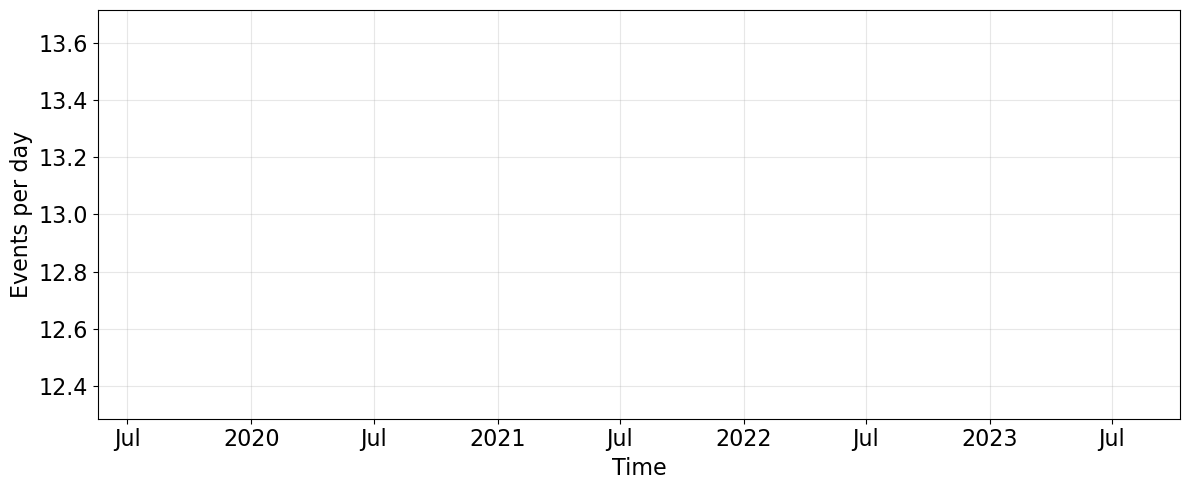

time
2021-07-29 00:00:00+00:00    13
Freq: D, dtype: int64

In [34]:
fig, ax, counts = h.plot_event_count_time(
    catalog=df_catalog,
    time_col=catc.time,
    start=START,
    end=END,
    freq="D",
    figsize=(12, 5),
)

fig.savefig(IMAGE_DIR / "event_count_daily.svg", bbox_inches="tight")
plt.show()

display(counts.head())

## 2D seismicity map

Pavlof seismicity map from 2021-07-29 to 2021-07-30 (Size = Magnitude | Color = Depth)


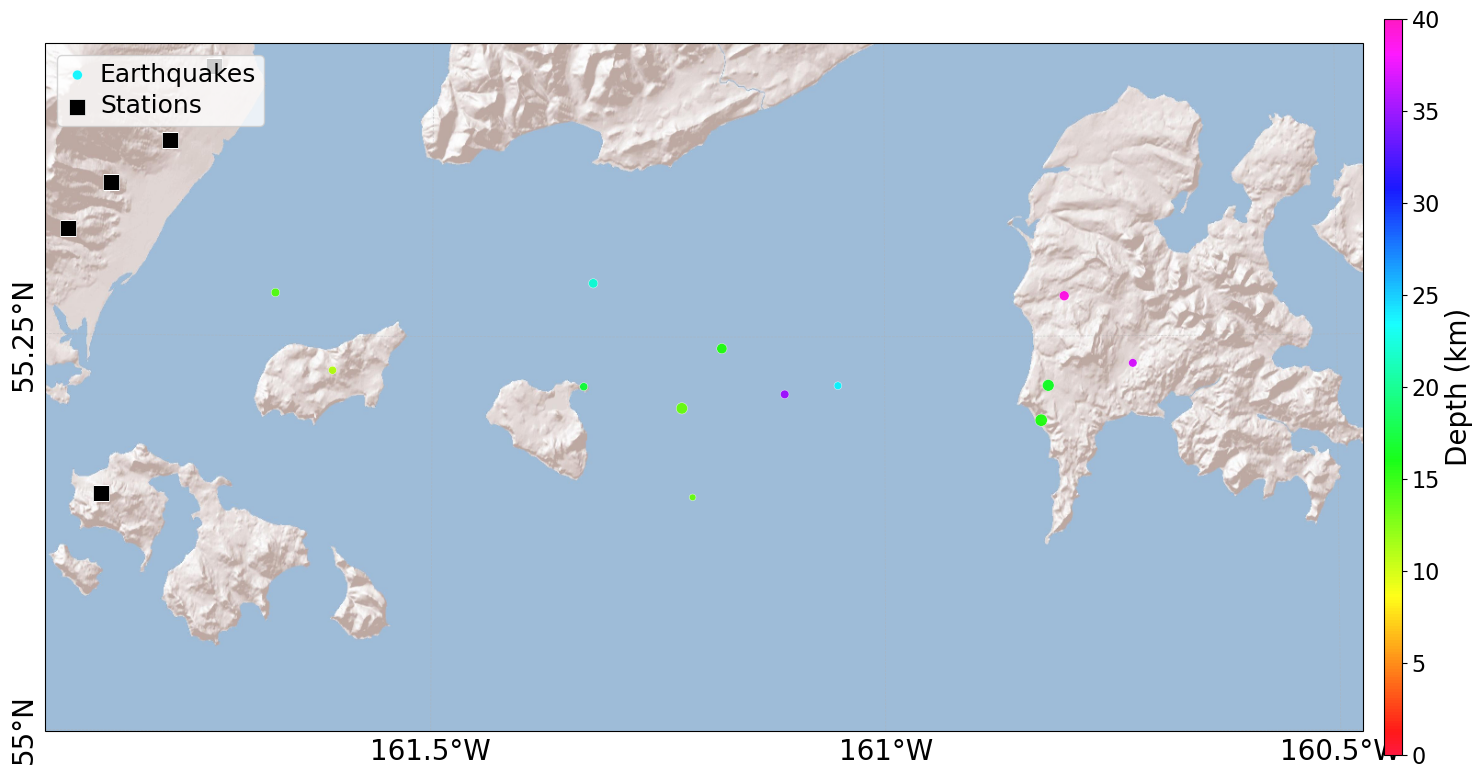

In [35]:
fig, ax = h.plot_mapview_seismicity(
    catalog=df_catalog,
    stations=df_stations,
    start=START,
    end=END,
    depth_vmin=0.0,
    depth_vmax=40.0,
    cmap_name="gist_rainbow",
    size_k=22.0,
    marker_min=6.0,
    plot_ellipse=False,
    relief_zoom=12,
    pad_lon=0.25,
    pad_lat=0.15,
    step_lon=0.5,
    step_lat=0.25,
    labelsize=20,
    figsize=(15, 8),
    savefig=False,
    dpi=600,
)

fig.savefig(IMAGE_DIR / "mapview_seismicity.svg", bbox_inches="tight")
plt.show()

## Basemap with stations only

Basemap from 2021-07-29 to 2021-07-30 without seismicity


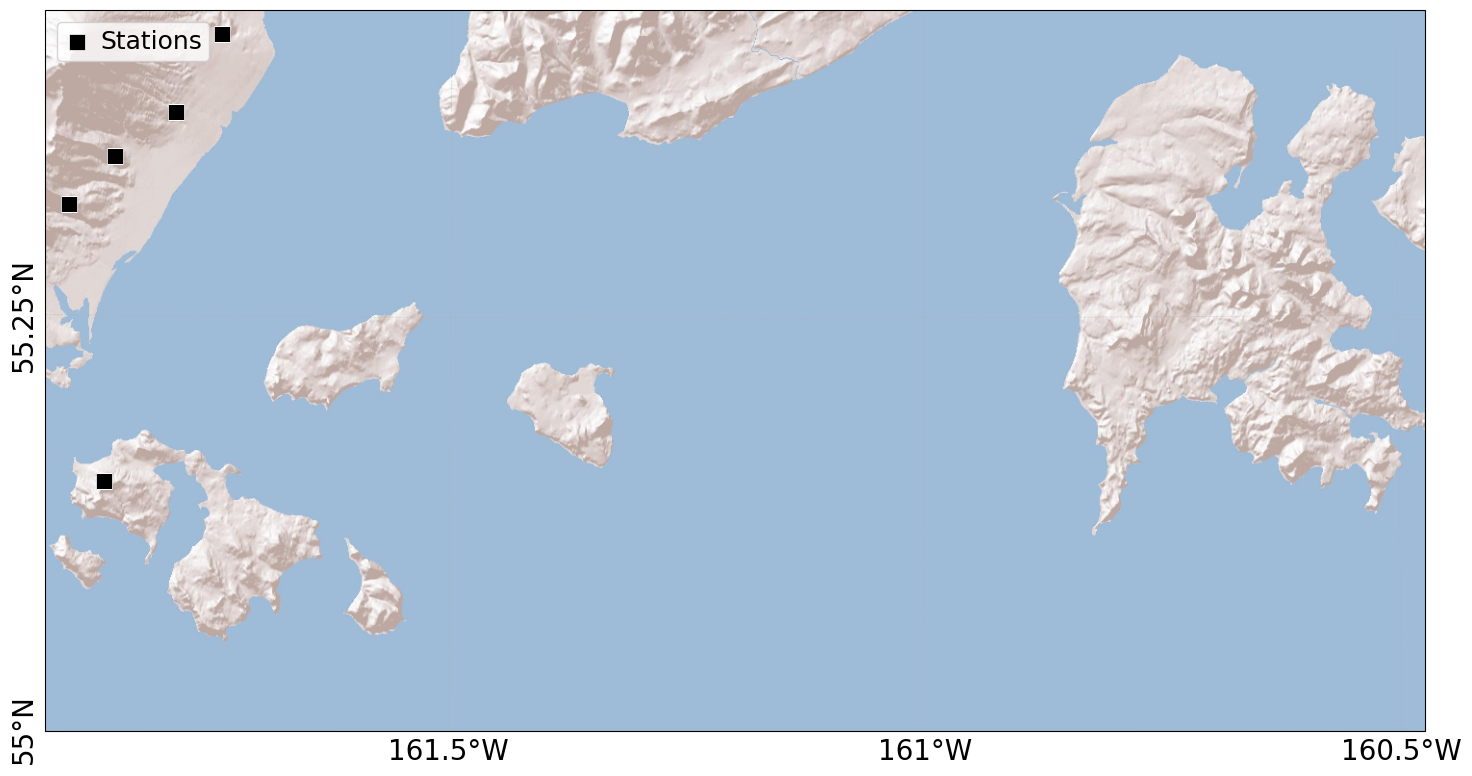

In [36]:
fig, ax = h.plot_mapview_basemap_stations(
    catalog=df_catalog,
    stations=df_stations,
    start=START,
    end=END,
    relief_zoom=12,
    pad_lon=0.25,
    pad_lat=0.15,
    step_lon=0.5,
    step_lat=0.25,
    labelsize=20,
    figsize=(15, 8),
    savefig=False,
    dpi=600,
)

fig.savefig(IMAGE_DIR / "mapview_stations_only.svg", bbox_inches="tight")
plt.show()

## 3D map colored by time

In [37]:
# 3D interactive visualization: topography + seismicity

import plotly.io as pio

pio.renderers.default = "notebook_connected"

df_cat_plot = df_catalog.copy()
df_cat_plot["time"] = pd.to_datetime(df_cat_plot["time"], utc=True, errors="coerce")
df_cat_plot = df_cat_plot.dropna(subset=["time"]).copy()

start_dt = pd.to_datetime(START, utc=True)
end_dt = pd.to_datetime(END, utc=True)

df_cat_plot = df_cat_plot[
    (df_cat_plot["time"] >= start_dt) &
    (df_cat_plot["time"] <= end_dt)
].copy()

fig = h.plot_catalog_3d_topo_seismicity(
    catalog=df_cat_plot,
    catc=catc,
    mode="time",
    year=None,
    dem_res="15s",
    topo_exagg=3.0,
    topo_opacity=0.98,
    colorscale="Spectral",
    show=False,
    renderer="notebook_connected",
    save_image=None,
    image_format="svg",
    image_width=1200,
    image_height=900,
    image_engine="kaleido",
)

fig.write_html(IMAGE_DIR / "catalog_3d_interactive.html", include_plotlyjs="cdn")

fig.show(renderer="notebook_connected")

grdcut [WARNING]: (w - x_min) must equal (NX + eps) * x_inc), where NX is an integer and |eps| <= 0.0001.
grdcut [WARNING]: w reset from -161.673844 to -161.675
grdcut [WARNING]: (e - x_min) must equal (NX + eps) * x_inc), where NX is an integer and |eps| <= 0.0001.
grdcut [WARNING]: e reset from -160.725781 to -160.725
grdcut [WARNING]: (s - y_min) must equal (NY + eps) * y_inc), where NY is an integer and |eps| <= 0.0001.
grdcut [WARNING]: s reset from 55.148739 to 55.1458333333
grdcut [WARNING]: (n - y_min) must equal (NY + eps) * y_inc), where NY is an integer and |eps| <= 0.0001.
grdcut [WARNING]: n reset from 55.283838 to 55.2875


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers_integrated.py:1821: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result

grdcut [WARNING]: (w - x_min) must equal (NX + eps) * x_inc), where NX is an integer and |eps| <= 0.0001.


grdcut [WARNING]: w reset from -161.673844 to -161.675
grdcut [WARNING]: (e - x_min) must equal (NX + eps) * x_inc), where NX is an integer and |eps| <= 0.0001.
grdcut [WARNING]: e reset from -160.725781 to -160.725
grdcut [WARNING]: (s - y_min) must equal (NY + eps) * y_inc), where NY is an integer and |eps| <= 0.0001.
grdcut [WARNING]: s reset from 55.148739 to 55.1458333333
grdcut [WARNING]: (n - y_min) must equal (NY + eps) * y_inc), where NY is an integer and |eps| <= 0.0001.
grdcut [WARNING]: n reset from 55.283838 to 55.2875


Número de eventos después de filtros (time, depth<=50.0 km): 13


NameError: name 'sizes' is not defined

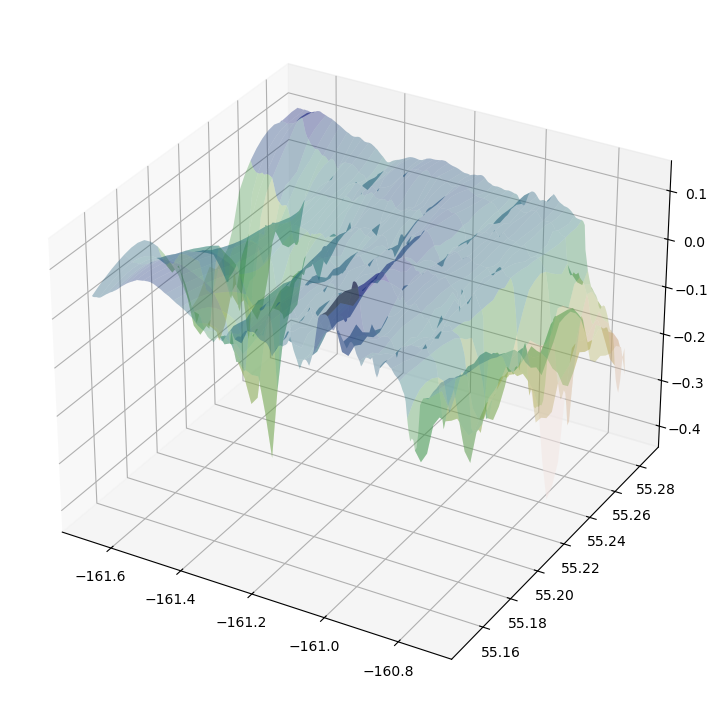

In [38]:
fig, ax, meta = h.plot_mapview3d_timecolor(
    catalog=df_catalog,
    start=START,
    end=END,
    depth_max=DEPTH_MAX,
    dem_res="15s",
    exagg=EXAGG,
    topo_cmap="gist_earth_r",
    quake_cmap="magma",
    size_k=1.0,
    topo_alpha=0.35,
    topo_stride=5,
    view_elev=VIEW_ELEV,
    view_azim=VIEW_AZIM,
    n_xticks=5,
    n_yticks=5,
    tick_fontsize=13,
    cbar_tick_fontsize=18,
    figsize=(12, 9),
    savefig=False,
    dpi=800,
    catc=catc,
)

fig.savefig(IMAGE_DIR / "mapview3d_timecolor.svg", bbox_inches="tight")
plt.show()

print(meta)

## Zoomed 2D seismicity map

Seismicity map from 2021-07-29 to 2021-07-30 (Size = Magnitude | Color = Depth)


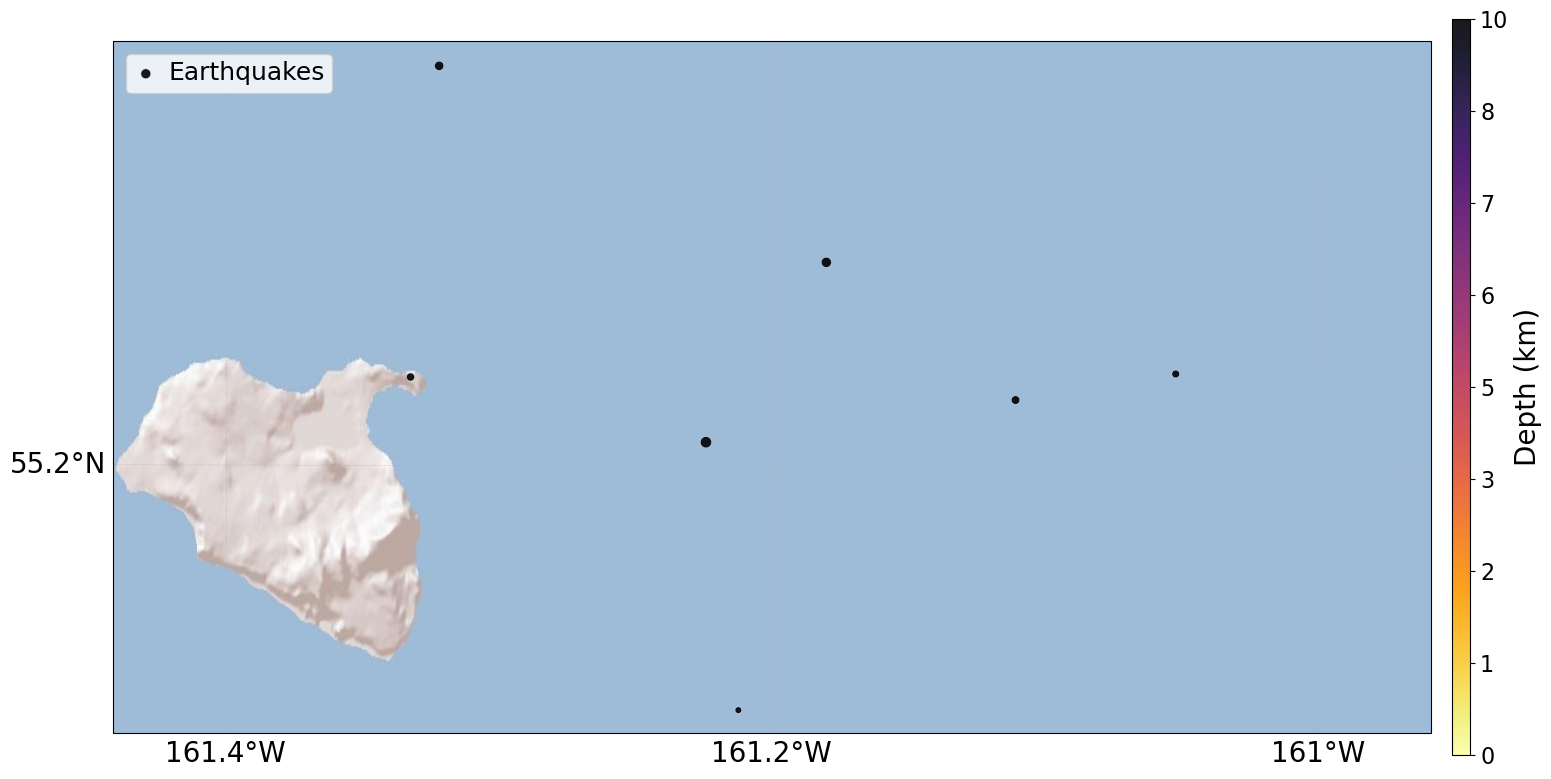

{'bounds': (-161.44115633333334, -160.95846866666668, 55.143772000000006, 55.288805), 'center': (-161.1998125, 55.216288500000005)}


In [39]:
fig, ax, meta = h.plot_mapview_seismicity_zoom(
    catalog=df_catalog,
    start=START,
    end=END,
    depth_vmin=0.0,
    depth_vmax=10.0,
    cmap_name="inferno_r",
    size_k=22.0,
    marker_min=6.0,
    plot_ellipse=False,
    relief_zoom=12,
    pad_lon=0.25,
    pad_lat=0.15,
    step_lon=0.2,
    step_lat=0.1,
    labelsize=20,
    figsize=(15, 8),
    dpi=600,
    zoom_factor=3,
    show=False,
)

fig.savefig(IMAGE_DIR / "mapview_zoom.svg", bbox_inches="tight")
plt.show()

print(meta)

## Optional timeline with spans



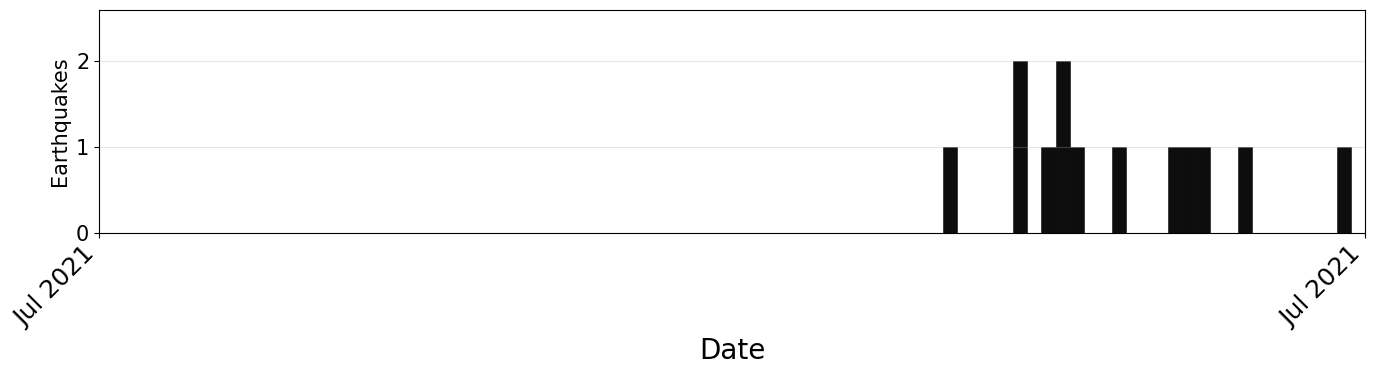

13


In [40]:
spans = [
    ("2021-01-01", "2021-06-01", "Swarm A"),
    ("2022-03-01", "2022-05-15", "Swarm B"),
    ("2023-07-01", "2023-09-01", "Unrest"),
]

fig, ax, meta = h.plot_timeline_histogram(
    catalog=df_catalog,
    start=START,
    end=END,
    spans=spans,
    time_col=catc.time,
    fi_col="FI",  # if absent, helper uses EVENTS
    n_bins=90,
    figsize=(14, 4),
    show_legend=False,
    savefig=False,
    dpi=600,
)

fig.savefig(IMAGE_DIR / "timeline_histogram.svg", bbox_inches="tight")
plt.show()

print(meta["n_events"])

## Optional cross section

In [34]:
PROFILE = {
    "start_lon": -158.2729,
    "start_lat": 56.87708,
    "end_lon": -157.9812,
    "end_lat": 56.87708,
    "label_start": "C'",
    "label_end": "C",
    "swath_km": 5.0,
}

Pavlof seismicity map from 2021-01-01 to 2024-12-31 (Size = Magnitude | Color = Depth)


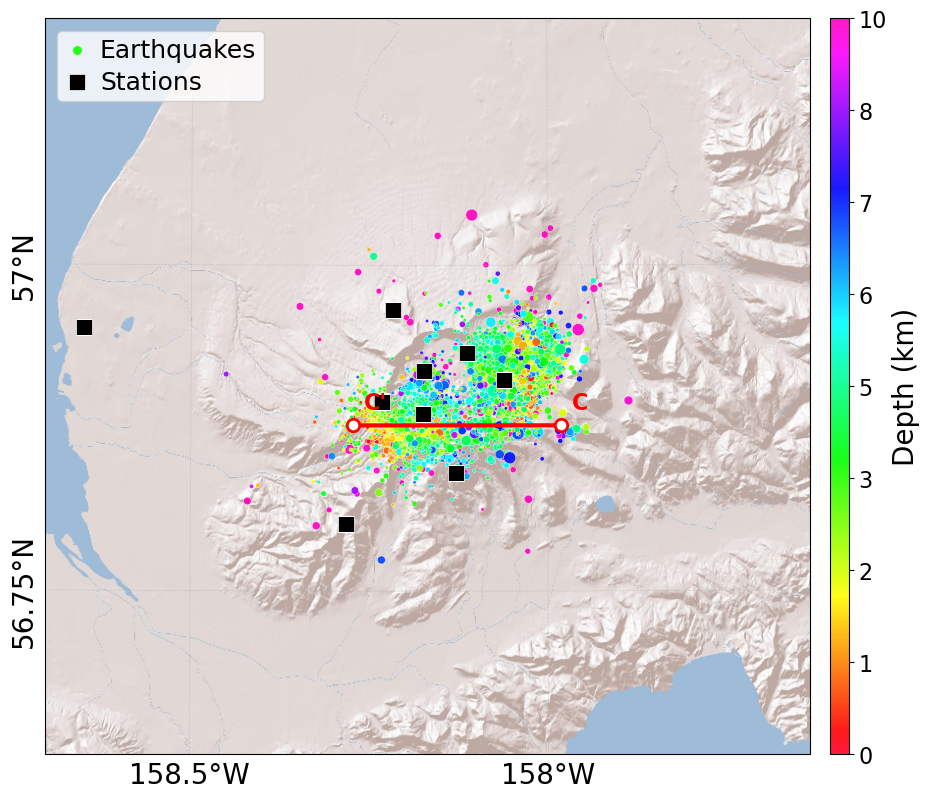

In [35]:
fig, ax = h.plot_mapview_seismicity(
    catalog=df_catalog,
    stations=df_stations,
    start=START,
    end=END,
    depth_vmin=0.0,
    depth_vmax=10.0,
    cmap_name="gist_rainbow",
    size_k=22.0,
    marker_min=6.0,
    plot_ellipse=False,
    relief_zoom=12,
    pad_lon=0.25,
    pad_lat=0.15,
    step_lon=0.5,
    step_lat=0.25,
    labelsize=20,
    figsize=(15, 8),
    savefig=False,   # importante: guardar después de añadir la línea
    dpi=600,
)

h.add_profile_line(
    ax=ax,
    start_lon=PROFILE["start_lon"],
    start_lat=PROFILE["start_lat"],
    end_lon=PROFILE["end_lon"],
    end_lat=PROFILE["end_lat"],
    start_label=PROFILE["label_start"],
    end_label=PROFILE["label_end"],
    line_color="red",
    line_width=3.0,
    marker_size=80,
    fontsize=16,
)

fig.savefig(IMAGE_DIR / "mapview_seismicity_with_crosssection.pdf", bbox_inches="tight")
fig.savefig(IMAGE_DIR / "mapview_seismicity_with_crosssection.svg", bbox_inches="tight")
fig.savefig(IMAGE_DIR / "mapview_seismicity_with_crosssection.png", dpi=600, bbox_inches="tight")

plt.show()

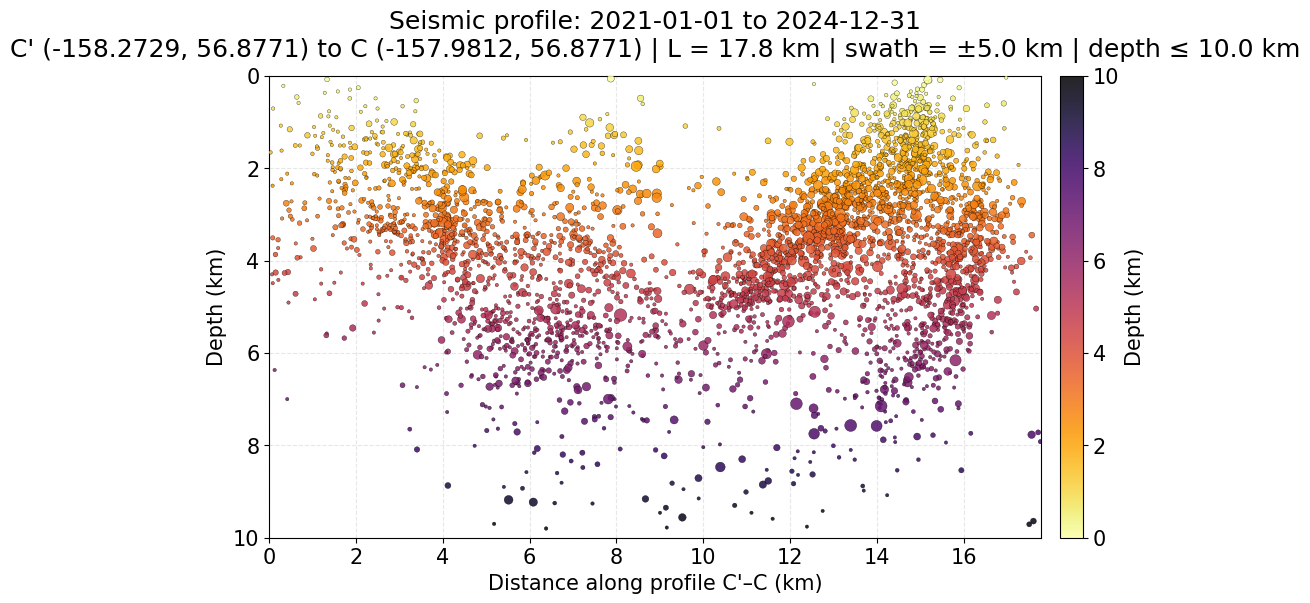

{'profile_length_km': 17.785637862067137, 'azimuth_deg': 89.87785051795235, 'n_events': 3804, 'swath_km': 5.0, 'depth_max_plot': 10.0, 'start': (-158.2729, 56.87708), 'end': (-157.9812, 56.87708), 'distance_col': 'distance_km', 'across_col': 'across_km', 'projected_catalog':              lon        lat  depth   mag                         datetime  \
0    -158.270475  56.860978   3.87  0.55 2023-01-01 00:51:58.940000+00:00   
2    -158.086361  56.873881   8.85  1.28 2023-01-01 19:02:43.320000+00:00   
5    -158.001058  56.916870   2.08  0.86 2023-01-02 05:23:19.050000+00:00   
6    -158.164697  56.867090   3.93  0.63 2023-01-02 05:33:43.340000+00:00   
7    -158.241732  56.860872   1.13  0.75 2023-01-02 06:44:32.620000+00:00   
...          ...        ...    ...   ...                              ...   
6417 -158.033366  56.917936   1.68  0.69 2023-10-30 15:49:03.480000+00:00   
6420 -158.083138  56.919560   3.82  1.16 2023-11-16 18:17:48.280000+00:00   
6421 -158.170492  56.875594   4

In [36]:
fig, ax, meta = h.plot_cross_section_seismicity(
    catalog=df_catalog,
    start=START,
    end=END,
    start_lon=PROFILE["start_lon"],
    start_lat=PROFILE["start_lat"],
    end_lon=PROFILE["end_lon"],
    end_lat=PROFILE["end_lat"],
    catc=catc,
    swath_km=PROFILE["swath_km"],
    depth_vmin=0.0,
    depth_vmax=DEPTH_MAX,
    depth_max_plot=DEPTH_MAX,
    cmap_name="inferno_r",
    size_k=22.0,
    marker_min=6.0,
    x_label_start=PROFILE["label_start"],
    x_label_end=PROFILE["label_end"],
    figsize=(12, 6),
)

fig.savefig(IMAGE_DIR / "cross_section_profile_C.svg", bbox_inches="tight")
plt.show()

print(meta)